# Fashion MNIST — Neural Network Practical Tasks

**Level:** Beginner → Intermediate  
**Tools:** Python, TensorFlow/Keras, Matplotlib  
**Goal:** Experiment with a Neural Network and understand what changes its performance.

## Before You Start

- Load the **Fashion MNIST** dataset.
- Keep a separate **validation set** from the training data (or use `validation_split=0.2`).
- Normalize image pixels to the range **0–1**.
- Use the **same train/validation split** for all comparisons.
- Evaluate final models on `x_test` only after choosing the model settings.
- Change **one setting at a time** unless the task says otherwise.

**Baseline model (use for most tasks):**

| Layer | Configuration |
|---|---|
| Input | `28 × 28` |
| Flatten | Convert image to 784 values |
| Dense | 32 neurons, `relu` |
| Dense (output) | 10 neurons, `softmax` |

**Compile:** `optimizer='adam'`, `loss='sparse_categorical_crossentropy'`, `metrics=['accuracy']`  
**Default training:** `epochs=10`, `batch_size=32`.

---

## Task 1 — Explore the Dataset

1. Print the shapes of the training and testing data.
2. Print the number of classes and their names.
3. Display **10 images** with their labels.
4. Count the training images in each class.

**Answer:** Why do we normalize pixel values? Is the dataset balanced?

## Task 2 — Train a Baseline Model

1. Build the baseline model shown above.
2. Train it for **10 epochs**.
3. Report training accuracy, validation accuracy, and final test accuracy.
4. Plot `loss` vs. `val_loss` and `accuracy` vs. `val_accuracy`.

**Answer:** What is the purpose of `Flatten`, `ReLU`, and `Softmax`?

## Task 3 — Analyze Predictions

1. Select **3 test images**: at least **one correct** and **one incorrect** prediction (if available).
2. Show each image with its **true label** and **predicted label**.
3. Show the predicted probability for the chosen class.

**Answer:** How does the image move through the model (forward pass)? For an incorrect prediction, what might make the two clothing classes confusing? **Do not claim to know the exact reason from the prediction alone.**

## Task 4 — Compare Epochs

Train a **fresh model each time** with **5, 10, and 20 epochs**. Keep everything else the same.

1. Plot training/validation loss and accuracy for each run.
2. Compare the **best validation accuracy**.
3. Check whether validation performance stops improving while training performance keeps improving.

**Answer:** Which run shows signs of overfitting? Is more training always better?

## Task 5 — EarlyStopping Experiment

Use **40 epochs** as the maximum. Compare:

- **Run A:** Without `EarlyStopping`.
- **Run B:** With `EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)`.
- **Run C:** With `EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)`.

1. Record the number of epochs actually trained.
2. Compare the best validation loss and final validation accuracy.

**Answer:** What does `patience=3`,`5` mean? Why might EarlyStopping help?

## Task 6 — Hidden Neurons Experiment

Train fresh models with **16, 32, and 128 neurons** in the hidden layer.

1. Keep epochs, batch size, optimizer, and data split fixed.
2. Compare training and validation accuracy.
3. Record training time if possible.

**Answer:** Did adding neurons always improve validation accuracy? What is the trade-off?

## Task 7 — Batch Size Experiment

Train fresh models using `batch_size` values **8, 32, and 128**.

1. Keep the architecture, optimizer, and epochs fixed.
2. Compare validation accuracy and time per epoch.
3. Plot the loss curves.

**Answer:** How does batch size change the number of weight updates per epoch? Which batch size worked best in your experiment?

## Task 8 — Optimizer Comparison

Use the same architecture and training settings with:

- `SGD(learning_rate=0.01)`
- `SGD(learning_rate=0.01, momentum=0.9)`
- `Adam(learning_rate=0.001)`

1. Plot the training and validation loss curves.
2. Compare validation accuracy after 10 epochs.

**Answer:** Which optimizer improved fastest in your results? How is Momentum different from basic SGD?

**Optional challenge:** Try `AdamW` and compare it with Adam.

## Task 9 — Activation Function Comparison

Replace the **hidden-layer** ReLU with:

- `tanh`
- `gelu` **(optional)**

Keep **Softmax in the output layer** unchanged.

1. Train each version with the same settings.
2. Compare the loss curves and validation accuracy.

**Answer:** Which hidden activation worked best for this model? Does one experiment prove it is always better?

## Task 10 — Evaluate the Final Model

Choose the model configuration with the best validation result.

1. Evaluate it **once** on the test set.
2. Draw a **Confusion Matrix**.
3. Find **two classes** the model often confuses.
4. Display **three incorrect predictions** with true and predicted labels.

**Answer:** Which clothing categories are hardest for the model? Suggest one improvement to test next.

---

## What to Submit

- **One Jupyter Notebook** with code, outputs, and plots.
- **One small comparison table** listing each experiment, the setting changed, and its validation accuracy.
- **1–2 sentences** answering the questions under each task.
- A short conclusion: **Which configuration did you choose, and why?**

**Important:** The goal is to **explain the results**, not just get the highest accuracy. Results may differ slightly between runs because training involves randomness.


In [1]:
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
# split the data into training, validation, and test sets
(x_train, y_train),(x_test,y_test)  =keras.datasets.fashion_mnist.load_data()
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)

# normalize the data
x_train = x_train / 255.0
x_val = x_val / 255.0
x_test = x_test / 255.0


Training set shape: (48000, 28, 28)
Validation set shape: (12000, 28, 28)
Test set shape: (10000, 28, 28)
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


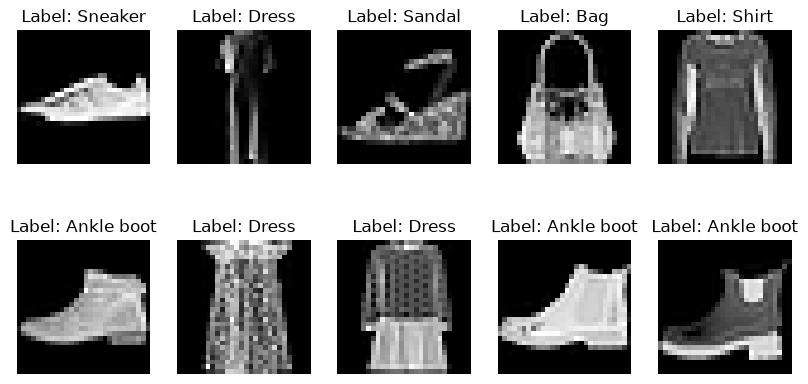

Number of training images in class 'T-shirt/top': 4798
Number of training images in class 'Trouser': 4781
Number of training images in class 'Pullover': 4795
Number of training images in class 'Dress': 4816
Number of training images in class 'Coat': 4798
Number of training images in class 'Sandal': 4789
Number of training images in class 'Shirt': 4782
Number of training images in class 'Sneaker': 4841
Number of training images in class 'Bag': 4803
Number of training images in class 'Ankle boot': 4797


In [3]:
# Task 1.1 print the shape of the training, validation, and test sets
print("Training set shape:", x_train.shape)
print("Validation set shape:", x_val.shape)
print("Test set shape:", x_test.shape)

# Task 1.2 print the number of classes and their names
num_classes = len(np.unique(y_train))
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print("Number of classes:", num_classes)        
print("Class names:", class_names)

# task 1.3 display 10 images with their labels
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Label: {class_names[y_train[i]]}')
    plt.axis('off')
plt.show()

# Task 1.4 count the training images in each class
for i in range(num_classes):
    count = np.sum(y_train == i)
    print(f"Number of training images in class '{class_names[i]}': {count}")

# Answer: Why do we normalize pixel values? Is the dataset balanced?
#   Normalizing pixel values helps in faster convergence during training and ensures that all features contribute equally to the loss function. 
#   The dataset appears to be relatively balanced, as the number of images in each class is similar.

c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8054 - loss: 0.5703 - val_accuracy: 0.8280 - val_loss: 0.4903
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8519 - loss: 0.4270 - val_accuracy: 0.8549 - val_loss: 0.4065
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8600 - loss: 0.3901 - val_accuracy: 0.8516 - val_loss: 0.4096
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8684 - loss: 0.3674 - val_accuracy: 0.8627 - val_loss: 0.3807
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8717 - loss: 0.3529 - val_accuracy: 0.8648 - val_loss: 0.3743
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8768 - loss: 0.3397 - val_accuracy: 0.8677 - val_loss: 0.3731
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8806 - loss: 0.3283 - val_accuracy: 0.8739 - val_loss: 0.3530
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8840 - loss: 0.3191 - 

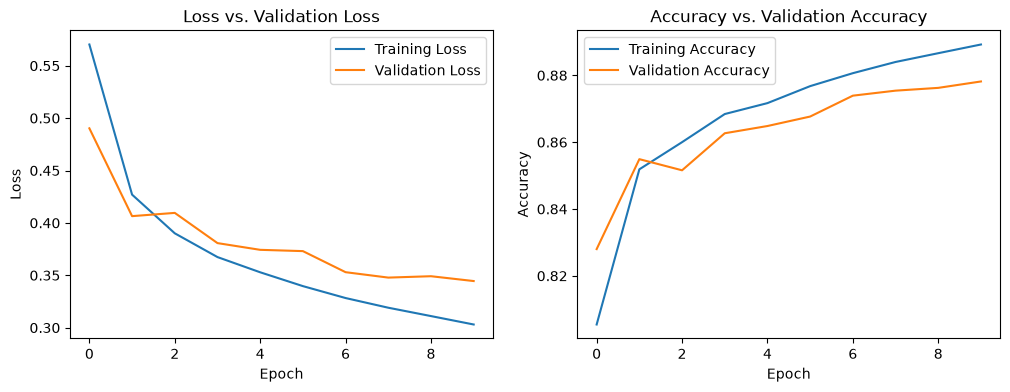

In [4]:
# Task 2.1 Build the baseline model shown above.
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
# Task 2.2 Train the model using 10 epochs
history = model.fit(x_train, y_train, epochs=10, validation_data=(x_val, y_val))

# task 2.3 Report training accuracy, validation accuracy, and final test accuracy.
train_accuracy = history.history['accuracy'][-1]
val_accuracy = history.history['val_accuracy'][-1]
test_accuracy = model.evaluate(x_test, y_test, verbose=0)[1]
print(f"Training Accuracy: {train_accuracy}")
print(f"Validation Accuracy: {val_accuracy}")
print(f"Test Accuracy: {test_accuracy}")

# Task 2.4 Plot loss vs. val_loss and accuracy vs. val_accuracy.
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# What is the purpose of Flatten, ReLU, and Softmax?
# Flatten: Converts the 2D image data into a 1D array, making it suitable for feeding into fully connected layers.
# ReLU: Introduces non-linearity into the model, allowing it to learn complex patterns.
# Softmax: Converts the output of the final layer into a probability distribution, making it suitable for multi-class classification.

# Task 3 — Analyze Predictions

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step


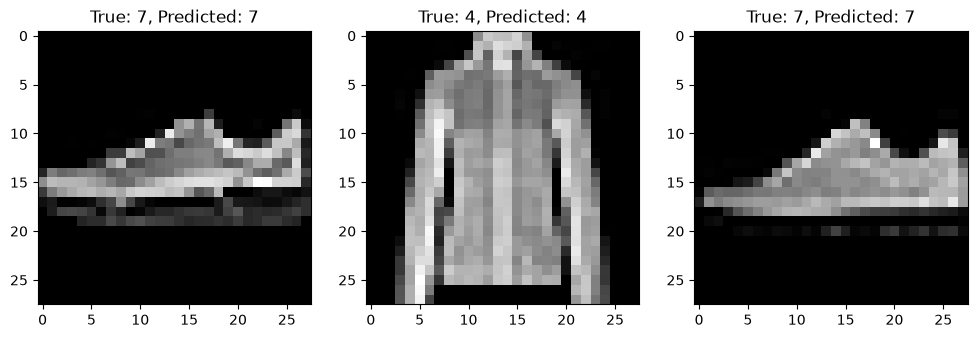

Predicted probability for true class (Image 1): 0.99747234582901
Predicted probability for true class (Image 2): 0.6691595315933228
Predicted probability for true class (Image 3): 0.9997697472572327


In [5]:
# Task 3.1 Select 3 test images: at least one correct and one incorrect prediction (if available).
test_predictions = model.predict(x_test)
img1 = x_test[9]
img2 = x_test[57]
img3 = x_test[102]

# Task 3.2 Show each image with its true label and predicted label. 
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img1, cmap='gray')
plt.title(f'True: {y_test[9]}, Predicted: {test_predictions[9].argmax()}')

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap='gray')
plt.title(f'True: {y_test[57]}, Predicted: {test_predictions[57].argmax()}')

plt.subplot(1, 3, 3)
plt.imshow(img3, cmap='gray')
plt.title(f'True: {y_test[102]}, Predicted: {test_predictions[102].argmax()}')
plt.show()

# Task 3.3 Show the predicted probability for the chosen class.
print(f"Predicted probability for true class (Image 1): {test_predictions[9][y_test[9]]}")
print(f"Predicted probability for true class (Image 2): {test_predictions[57][y_test[57]]}")
print(f"Predicted probability for true class (Image 3): {test_predictions[102][y_test[102]]}")

# How does the image move through the model (forward pass)?
# The image is first flattened into a 1D array, then passed through the first dense layer with ReLU activation, 
# which introduces non-linearity. The output is then passed through the second dense layer with softmax activation, 
# which produces a probability distribution over the 10 classes.

# For an incorrect prediction, what might make the two clothing classes confusing?
# Some clothing classes may have similar visual features, such as color, shape, or texture, which can lead to confusion. 


# Task 4 — Compare Epochs
####    train a fresh model each time with 5, 10, and 20 epochs. Keep everything else the same
- Plot training/validation loss and accuracy for each run.
- Compare the best validation accuracy.
- Check whether validation performance stops improving while training performance keeps improving.

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8043 - loss: 0.5747 - val_accuracy: 0.8412 - val_loss: 0.4533
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8499 - loss: 0.4275 - val_accuracy: 0.8539 - val_loss: 0.4118
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8613 - loss: 0.3928 - val_accuracy: 0.8612 - val_loss: 0.3929
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8694 - loss: 0.3681 - val_accuracy: 0.8565 - val_loss: 0.4067
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8744 - loss: 0.3517 - val_accuracy: 0.8684 - val_loss: 0.3626


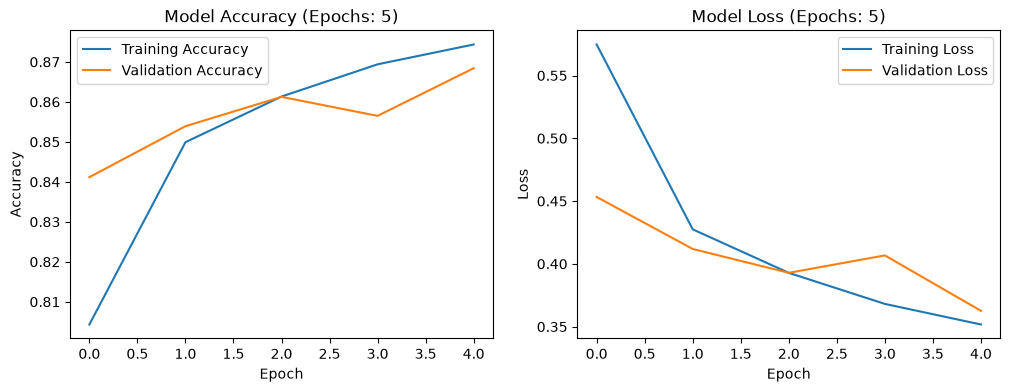

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8065 - loss: 0.5650 - val_accuracy: 0.8462 - val_loss: 0.4420
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8515 - loss: 0.4205 - val_accuracy: 0.8500 - val_loss: 0.4239
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8615 - loss: 0.3850 - val_accuracy: 0.8597 - val_loss: 0.3908
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8673 - loss: 0.3627 - val_accuracy: 0.8677 - val_loss: 0.3723
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8742 - loss: 0.3465 - val_accuracy: 0.8702 - val_loss: 0.3654
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8796 - loss: 0.3307 - val_accuracy: 0.8636 - val_loss: 0.3813
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8826 - loss: 0.3208 - val_accuracy: 0.8661 - val_loss: 0.3879
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8872 - loss: 0.3109 - 

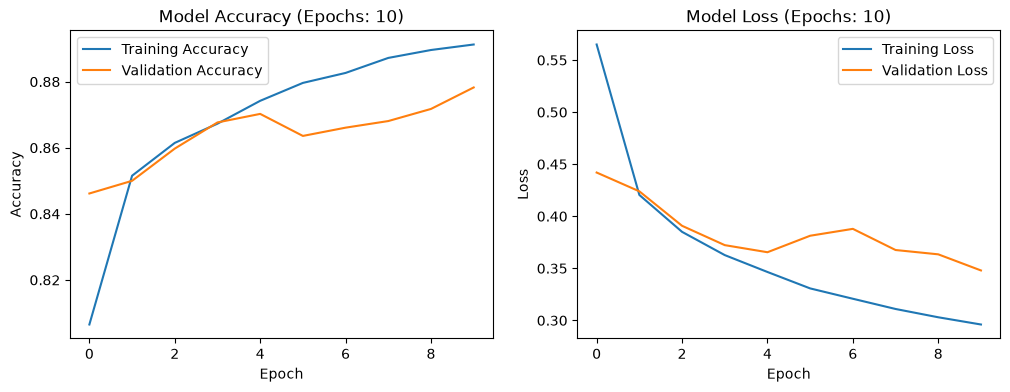

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8073 - loss: 0.5609 - val_accuracy: 0.8354 - val_loss: 0.4667
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8528 - loss: 0.4202 - val_accuracy: 0.8550 - val_loss: 0.4086
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8610 - loss: 0.3901 - val_accuracy: 0.8575 - val_loss: 0.4045
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8680 - loss: 0.3665 - val_accuracy: 0.8627 - val_loss: 0.3853
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8751 - loss: 0.3483 - val_accuracy: 0.8681 - val_loss: 0.3701
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8786 - loss: 0.3345 - val_accuracy: 0.8712 - val_loss: 0.3591
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8840 - loss: 0.3207 - val_accuracy: 0.8698 - val_loss: 0.3594
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8883 - loss: 0.3110 - 

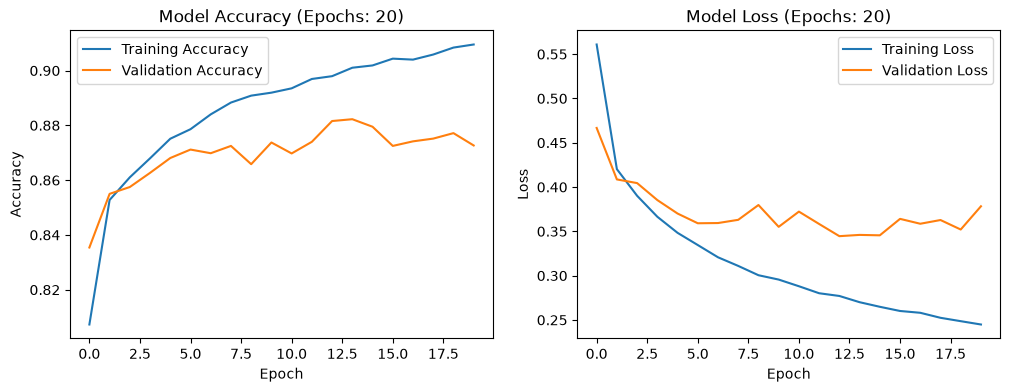

Validation Accuracies for different epochs:
Epochs: 5, Validation Accuracy: 0.8684166669845581
Epochs: 10, Validation Accuracy: 0.878250002861023
Epochs: 20, Validation Accuracy: 0.8822500109672546


In [6]:
epochs = [5, 10, 20]
val_accuracies = {}

for e in epochs: 
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=e, validation_data=(x_val, y_val))
    val_accuracies[e] = max(history.history['val_accuracy'])
    
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'Model Accuracy (Epochs: {e})')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Model Loss (Epochs: {e})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()
    
print("===========================================")
print(f"Validation Accuracies for different epochs:")
for e, acc in val_accuracies.items():
    print(f"Epochs: {e}, Validation Accuracy: {acc}")
    


## Task 5 — EarlyStopping Experiment

Use **40 epochs** as the maximum. Compare:

- **Run A:** Without `EarlyStopping`.
- **Run B:** With `EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)`.
- **Run C:** With `EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)`.

1. Record the number of epochs actually trained.
2. Compare the best validation loss and final validation accuracy.

**Answer:** What does `patience=3`,`5` mean? Why might EarlyStopping help?


In [7]:
print("Run A:")
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    x_train, 
    y_train, 
    epochs=40, 
    validation_data=(x_val, y_val), 
    batch_size=32
    )
num_epochs = len(history.history['accuracy'])
print(f"Number of epochs run: {num_epochs}")

best_val_loss = min(history.history['val_loss'])
print(f"Best validation loss: {best_val_loss}")
final_val_loss = history.history['val_loss'][-1]
print(f"Final validation loss: {final_val_loss}")

print("Run B:")
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
Early_stopping = keras.callbacks.EarlyStopping (
    patience = 3,
    restore_best_weights = True,
    monitor = "val_loss"
)
history = model.fit(
    x_train, 
    y_train, 
    epochs=40, 
    validation_data=(x_val, y_val), 
    batch_size=32, 
    callbacks=[Early_stopping]
    )
num_epochs = len(history.history['accuracy'])
print(f"Number of epochs run: {num_epochs}")
best_val_loss = min(history.history['val_loss'])
print(f"Best validation loss: {best_val_loss}")
final_val_loss = history.history['val_loss'][-1]
print(f"Final validation loss: {final_val_loss}")

print("Run C:")
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
Early_stopping = keras.callbacks.EarlyStopping (
    patience = 5,
    restore_best_weights = True,
    monitor = "val_loss"
)
history = model.fit(
    x_train, 
    y_train, 
    epochs=40, 
    validation_data=(x_val, y_val), 
    batch_size=32, 
    callbacks=[Early_stopping]
    )
num_epochs = len(history.history['accuracy'])
print(f"Number of epochs run: {num_epochs}")
best_val_loss = min(history.history['val_loss'])
print(f"Best validation loss: {best_val_loss}")
final_val_loss = history.history['val_loss'][-1]
print(f"Final validation loss: {final_val_loss}")



Run A:
Epoch 1/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8036 - loss: 0.5698 - val_accuracy: 0.8411 - val_loss: 0.4521
Epoch 2/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8518 - loss: 0.4233 - val_accuracy: 0.8524 - val_loss: 0.4123
Epoch 3/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8637 - loss: 0.3852 - val_accuracy: 0.8656 - val_loss: 0.3805
Epoch 4/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8702 - loss: 0.3639 - val_accuracy: 0.8690 - val_loss: 0.3671
Epoch 5/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8763 - loss: 0.3432 - val_accuracy: 0.8679 - val_loss: 0.3653
Epoch 6/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8812 - loss: 0.3300 - val_accuracy: 0.8748 - val_loss: 0.3544
Epoch 7/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8842 - loss: 0.3177 - val_accuracy: 0.8763 - val_loss: 0.3478
Epoch 8/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8869 - loss: 0.

## What does patience=3,5 mean? Why might EarlyStopping help?
- #### The patience parameter in EarlyStopping specifies the number of epochs to wait for an improvement in the monitored metric (in this case, validation loss) before stopping the training.


## Task 6 — Hidden Neurons Experiment

Train fresh models with **16, 32, and 128 neurons** in the hidden layer.

1. Keep epochs, batch size, optimizer, and data split fixed.
2. Compare training and validation accuracy.
3. Record training time if possible.

**Answer:** Did adding neurons always improve validation accuracy? What is the trade-off?


In [8]:
import time

neurons = [16, 32, 128]
train_accuracies = []
val_accuracies = []
training_times = []

for neuron in neurons:
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(neuron, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    Early_stopping = keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True,
        monitor="val_loss"
    )

    # 1. Record start time
    start_time = time.perf_counter()

    history = model.fit(
        x_train,
        y_train,
        epochs=40,
        validation_data=(x_val, y_val),
        batch_size=32,
        callbacks=[Early_stopping]
    )

    # 2. Record end time and compute elapsed seconds
    elapsed_time = time.perf_counter() - start_time
    training_times.append(elapsed_time)

    train_accuracies.append(max(history.history['accuracy']))
    val_accuracies.append(max(history.history['val_accuracy']))

    print(f"Model ({neuron} neurons) trained in {elapsed_time:.2f} seconds.")


Epoch 1/40


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7889 - loss: 0.6168 - val_accuracy: 0.8352 - val_loss: 0.4741
Epoch 2/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8447 - loss: 0.4479 - val_accuracy: 0.8490 - val_loss: 0.4324
Epoch 3/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8561 - loss: 0.4128 - val_accuracy: 0.8486 - val_loss: 0.4301
Epoch 4/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8626 - loss: 0.3946 - val_accuracy: 0.8594 - val_loss: 0.4019
Epoch 5/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8666 - loss: 0.3791 - val_accuracy: 0.8622 - val_loss: 0.3877
Epoch 6/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8708 - loss: 0.3676 - val_accuracy: 0.8659 - val_loss: 0.3764
Epoch 7/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8723 - loss: 0.3577 - val_accuracy: 0.8652 - val_loss: 0.3799
Epoch 8/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8753 - loss: 0.3502 - val_accurac

###  Did adding neurons always improve validation accuracy? What is the trade-off?
- ##### It did improve both accuracy and time

## Task 7 — Batch Size Experiment

Train fresh models using `batch_size` values **8, 32, and 128**.

1. Keep the architecture, optimizer, and epochs fixed.
2. Compare validation accuracy and time per epoch.
3. Plot the loss curves.

**Answer:** How does batch size change the number of weight updates per epoch? Which batch size worked best in your experiment?


Epoch 1/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - accuracy: 0.8224 - loss: 0.4943 - val_accuracy: 0.8562 - val_loss: 0.3947
Epoch 2/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.8617 - loss: 0.3737 - val_accuracy: 0.8672 - val_loss: 0.3692
Epoch 3/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - accuracy: 0.8764 - loss: 0.3369 - val_accuracy: 0.8651 - val_loss: 0.3719
Epoch 4/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step - accuracy: 0.8836 - loss: 0.3138 - val_accuracy: 0.8706 - val_loss: 0.3572
Epoch 5/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8888 - loss: 0.2990 - val_accuracy: 0.8802 - val_loss: 0.3377
Epoch 6/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8944 - loss: 0.2842 - val_accuracy: 0.8770 - val_loss: 0.3500
Epoch 7/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8980 - loss: 0.2722 - val_accuracy: 0.8758 - val_loss: 0.3617
Epoch 8/40
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9018 - loss: 0.2635

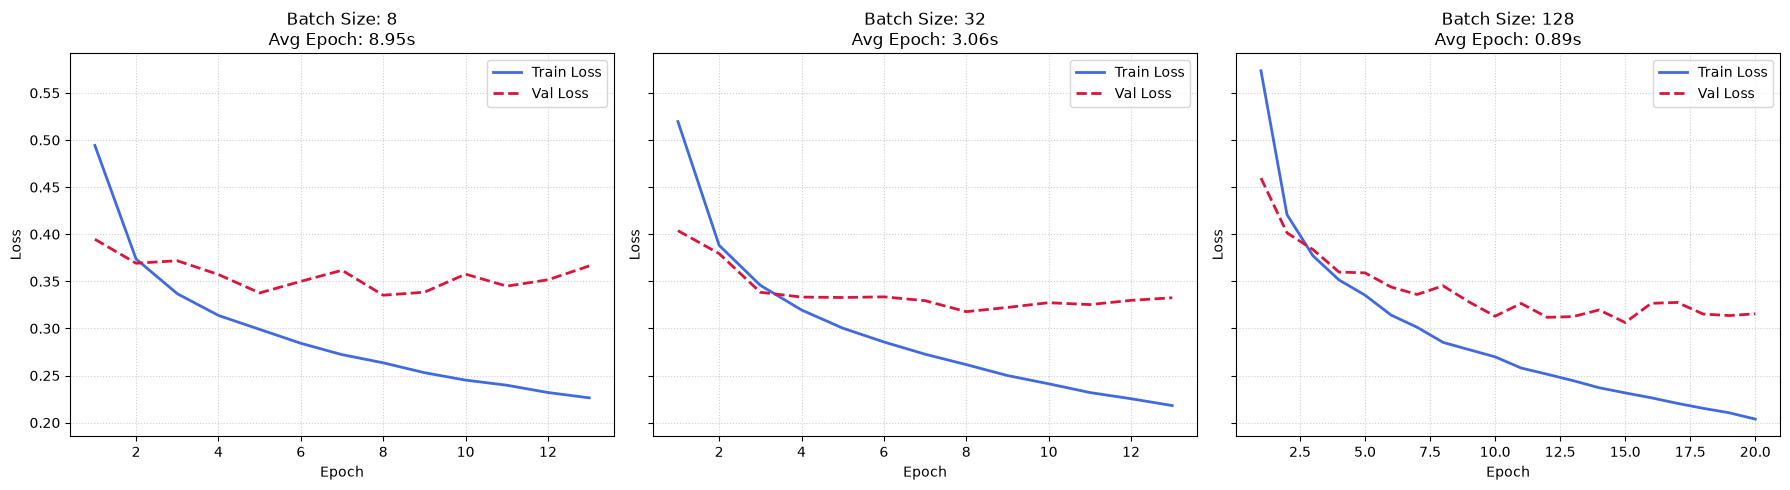

In [11]:
import time
import keras
import matplotlib.pyplot as plt

# Custom callback to capture per-epoch execution time
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.epoch_start
        self.epoch_times.append(elapsed)

batch_sizes = [8, 32, 128]
train_accuracies = []
val_accuracies = []
avg_epoch_times = []
all_epoch_times = []
histories = {}  # Dictionary to store training logs for plotting

for batch_size in batch_sizes:
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stopping = keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True,
        monitor="val_loss"
    )

    epoch_timer = EpochTimer()

    history = model.fit(
        x_train,
        y_train,
        epochs=40,
        validation_data=(x_val, y_val),
        batch_size=batch_size,
        callbacks=[early_stopping, epoch_timer]
    )

    # Save history object for plotting curves later
    histories[batch_size] = history.history

    epochs_duration = epoch_timer.epoch_times
    all_epoch_times.append(epochs_duration)

    mean_epoch_time = sum(epochs_duration) / len(epochs_duration)
    avg_epoch_times.append(mean_epoch_time)

    train_accuracies.append(max(history.history['accuracy']))
    val_accuracies.append(max(history.history['val_accuracy']))

    print(f"Batch size {batch_size} finished {len(epochs_duration)} epochs. "
          f"Average epoch time: {mean_epoch_time:.3f}s")


# ==========================================
# Plotting Loss Curves
# ==========================================
fig, axes = plt.subplots(1, len(batch_sizes), figsize=(6 * len(batch_sizes), 5), sharey=True)

# Ensure axes is iterable even if only one batch size is used
if len(batch_sizes) == 1:
    axes = [axes]

for ax, batch_size in zip(axes, batch_sizes):
    train_loss = histories[batch_size]['loss']
    val_loss = histories[batch_size]['val_loss']
    epochs_range = range(1, len(train_loss) + 1)

    ax.plot(epochs_range, train_loss, label='Train Loss', color='royalblue', linewidth=2)
    ax.plot(epochs_range, val_loss, label='Val Loss', color='crimson', linestyle='--', linewidth=2)
    
    ax.set_title(f"Batch Size: {batch_size}\nAvg Epoch: {avg_epoch_times[batch_sizes.index(batch_size)]:.2f}s")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()

### How does batch size change the number of weight updates per epoch? Which batch size worked best in your experiment?


## Task 8 — Optimizer Comparison

Use the same architecture and training settings with:

- `SGD(learning_rate=0.01)`
- `SGD(learning_rate=0.01, momentum=0.9)`
- `Adam(learning_rate=0.001)`

1. Plot the training and validation loss curves.
2. Compare validation accuracy after 10 epochs.

**Answer:** Which optimizer improved fastest in your results? How is Momentum different from basic SGD?

**Optional challenge:** Try `AdamW` and compare it with Adam.


Epoch 1/40


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8000 - loss: 0.5789 - val_accuracy: 0.8369 - val_loss: 0.4644
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8544 - loss: 0.4187 - val_accuracy: 0.8572 - val_loss: 0.3974
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8678 - loss: 0.3748 - val_accuracy: 0.8558 - val_loss: 0.4073
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8784 - loss: 0.3447 - val_accuracy: 0.8661 - val_loss: 0.3713
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8825 - loss: 0.3256 - val_accuracy: 0.8748 - val_loss: 0.3453
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8876 - loss: 0.3094 - val_accuracy: 0.8796 - val_loss: 0.3330
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8936 - loss: 0.2935 - val_accuracy: 0.8812 - val_loss: 0.3276
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8973 - loss: 0.2844 - val_accuracy: 0.8813 - val_

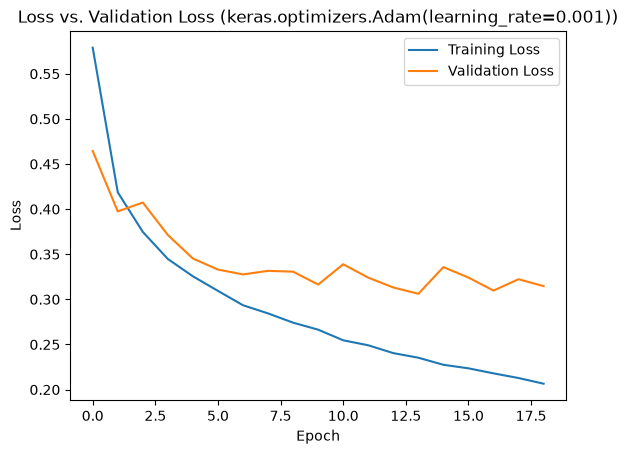

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9269 - loss: 0.2047 - val_accuracy: 0.8931 - val_loss: 0.2989
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9275 - loss: 0.2014 - val_accuracy: 0.8953 - val_loss: 0.2969
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9284 - loss: 0.2002 - val_accuracy: 0.8950 - val_loss: 0.2957
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9285 - loss: 0.1992 - val_accuracy: 0.8950 - val_loss: 0.2972
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9288 - loss: 0.1985 - val_accuracy: 0.8953 - val_loss: 0.2964
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9286 - loss: 0.1980 - val_accuracy: 0.8954 - val_loss: 0.2959
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9294 - loss: 0.1974 - val_accuracy: 0.8947 - val_loss: 0.2965
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9296 - loss: 0.1969 - val_accuracy: 0.

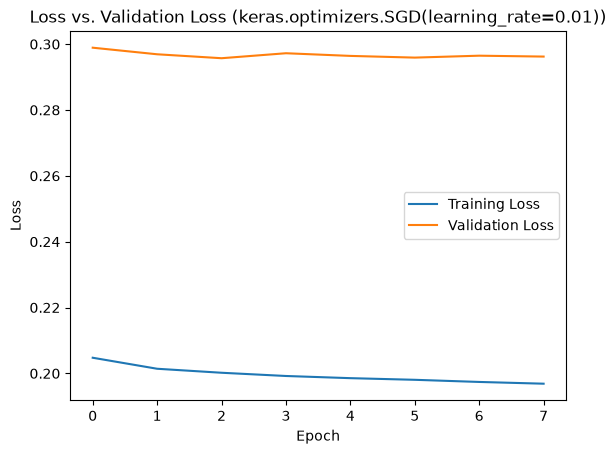

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9237 - loss: 0.2098 - val_accuracy: 0.8913 - val_loss: 0.3057
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9261 - loss: 0.2056 - val_accuracy: 0.8910 - val_loss: 0.3103
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9255 - loss: 0.2047 - val_accuracy: 0.8920 - val_loss: 0.3095
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9277 - loss: 0.2010 - val_accuracy: 0.8903 - val_loss: 0.3129
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9284 - loss: 0.2000 - val_accuracy: 0.8932 - val_loss: 0.3036
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9286 - loss: 0.1963 - val_accuracy: 0.8895 - val_loss: 0.3128
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9308 - loss: 0.1932 - val_accuracy: 0.8934 - val_loss: 0.3063
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9294 - loss: 0.1934 - val_accuracy: 0.

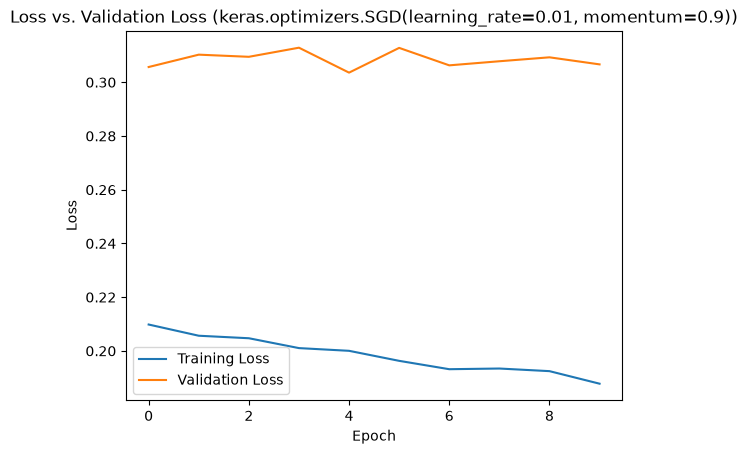

Validation Accuracies after 10 epochs for different optimizers:
Optimizer: keras.optimizers.Adam(learning_rate=0.001), Validation Accuracy: 0.8924999833106995
Optimizer: keras.optimizers.SGD(learning_rate=0.01), Validation Accuracy: 0.8954166769981384
Optimizer: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), Validation Accuracy: 0.893833339214325


In [12]:
import keras
import matplotlib.pyplot as plt

model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
        ])
optimizers = ['keras.optimizers.Adam(learning_rate=0.001)', 'keras.optimizers.SGD(learning_rate=0.01)', 'keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)']
val_acc_after_10_epochs = {}
for optimizer in optimizers:
    model.compile(
        optimizer=eval(optimizer),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
        )

    early_stopping = keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True,
        monitor="val_loss"
        )

    history = model.fit(
        x_train,
        y_train,
        epochs=40,
        validation_data=(x_val, y_val),
        batch_size=batch_size,
        callbacks=[early_stopping]
        )
    val_acc_after_10_epochs[optimizer] = max(history.history['val_accuracy'])
    print(f"Optimizer: {optimizer}")
    
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Loss vs. Validation Loss ({optimizer})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()
    
print("Validation Accuracies after 10 epochs for different optimizers:")
for optimizer, val_acc in val_acc_after_10_epochs.items():
    print(f"Optimizer: {optimizer}, Validation Accuracy: {val_acc}")
    

**Answer:** Which optimizer improved fastest in your results? How is Momentum different from basic SGD?


## Task 9 — Activation Function Comparison

Replace the **hidden-layer** ReLU with:

- `tanh`
- `gelu` **(optional)**

Keep **Softmax in the output layer** unchanged.

1. Train each version with the same settings.
2. Compare the loss curves and validation accuracy.

**Answer:** Which hidden activation worked best for this model? Does one experiment prove it is always better?


Epoch 1/40


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8019 - loss: 0.5814 - val_accuracy: 0.8404 - val_loss: 0.4577
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8532 - loss: 0.4210 - val_accuracy: 0.8588 - val_loss: 0.4022
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8661 - loss: 0.3775 - val_accuracy: 0.8460 - val_loss: 0.4240
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8751 - loss: 0.3507 - val_accuracy: 0.8734 - val_loss: 0.3636
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8821 - loss: 0.3315 - val_accuracy: 0.8698 - val_loss: 0.3661
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8873 - loss: 0.3140 - val_accuracy: 0.8791 - val_loss: 0.3381
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8896 - loss: 0.3037 - val_accuracy: 0.8817 - val_loss: 0.3298
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8972 - loss: 0.2871 - val_accuracy: 0.8760 - val_

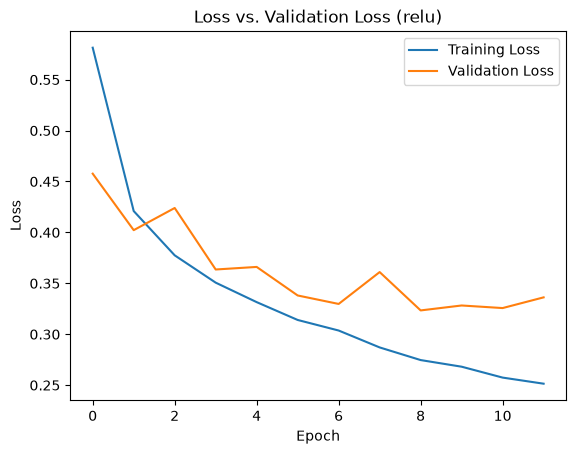

Activation: relu, Best Validation Accuracy: 0.8844166398048401
Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8062 - loss: 0.5579 - val_accuracy: 0.8428 - val_loss: 0.4403
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8554 - loss: 0.4066 - val_accuracy: 0.8619 - val_loss: 0.3822
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8686 - loss: 0.3680 - val_accuracy: 0.8668 - val_loss: 0.3623
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8736 - loss: 0.3462 - val_accuracy: 0.8730 - val_loss: 0.3503
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8821 - loss: 0.3248 - val_accuracy: 0.8714 - val_loss: 0.3444
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8860 - loss: 0.3130 - val_accuracy: 0.8734 - val_loss: 0.3394
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8920 - loss: 0.2963 - val_accuracy: 0.8832 - val_loss: 0.3240
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1

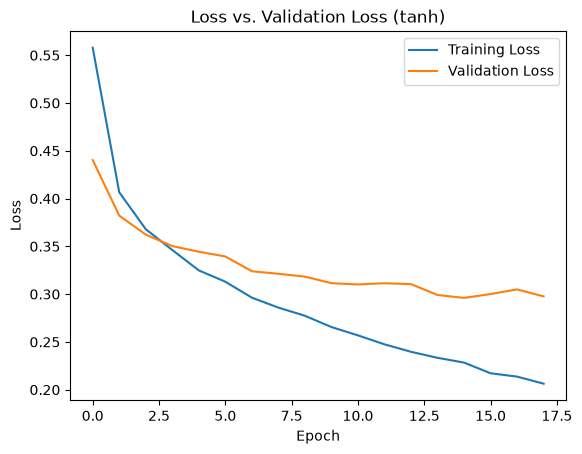

Activation: tanh, Best Validation Accuracy: 0.893833339214325
Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8076 - loss: 0.5677 - val_accuracy: 0.8517 - val_loss: 0.4366
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8548 - loss: 0.4130 - val_accuracy: 0.8649 - val_loss: 0.3878
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8690 - loss: 0.3718 - val_accuracy: 0.8682 - val_loss: 0.3723
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8753 - loss: 0.3479 - val_accuracy: 0.8255 - val_loss: 0.4769
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8829 - loss: 0.3268 - val_accuracy: 0.8739 - val_loss: 0.3510
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8882 - loss: 0.3085 - val_accuracy: 0.8754 - val_loss: 0.3453
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8939 - loss: 0.2935 - val_accuracy: 0.8771 - val_loss: 0.3355
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s

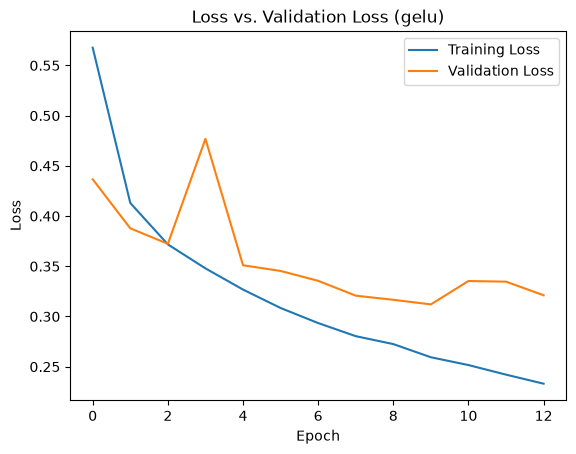

Activation: gelu, Best Validation Accuracy: 0.8882499933242798


In [13]:
activations = ['relu', 'tanh', "gelu"]
for activation in activations:
    model = keras.Sequential([
            keras.layers.Flatten(input_shape=(28, 28)),
            keras.layers.Dense(128, activation=activation),
            keras.layers.Dense(10, activation='softmax')
            ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
        )
    early_stopping = keras.callbacks.EarlyStopping(
        patience=3,
        restore_best_weights=True,
        monitor="val_loss"
        )
    history = model.fit(
        x_train,
        y_train,
        epochs=40,
        validation_data=(x_val, y_val),
        batch_size=batch_size,
        callbacks=[early_stopping]
        )
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Loss vs. Validation Loss ({activation})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()
    print(f"Activation: {activation}, Best Validation Accuracy: {max(history.history['val_accuracy'])}")
    


## Task 10 — Evaluate the Final Model

Choose the model configuration with the best validation result.

1. Evaluate it **once** on the test set.
2. Draw a **Confusion Matrix**.
3. Find **two classes** the model often confuses.
4. Display **three incorrect predictions** with true and predicted labels.

**Answer:** Which clothing categories are hardest for the model? Suggest one improvement to test next.


Epoch 1/40


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8025 - loss: 0.5638 - val_accuracy: 0.8405 - val_loss: 0.4371
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8546 - loss: 0.4082 - val_accuracy: 0.8588 - val_loss: 0.3844
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8664 - loss: 0.3717 - val_accuracy: 0.8684 - val_loss: 0.3652
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8758 - loss: 0.3470 - val_accuracy: 0.8675 - val_loss: 0.3550
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8811 - loss: 0.3281 - val_accuracy: 0.8776 - val_loss: 0.3370
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8862 - loss: 0.3132 - val_accuracy: 0.8732 - val_loss: 0.3466
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8902 - loss: 0.2997 - val_accuracy: 0.8761 - val_loss: 0.3360
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8938 - loss: 0.2896 - val_accuracy: 0.8798 - val_

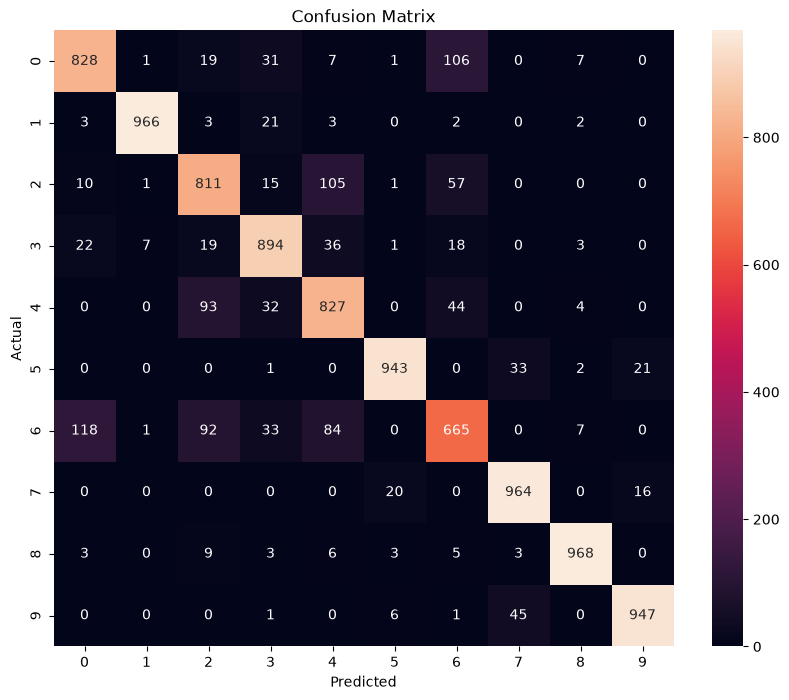

Top directional confusion: True 'Shirt' (class 6) predicted as 'T-shirt/top' (class 0) with 118 errors.

The two most confused classes are: 'T-shirt/top' (class 0) and 'Shirt' (class 6) with 224 total mutual errors.


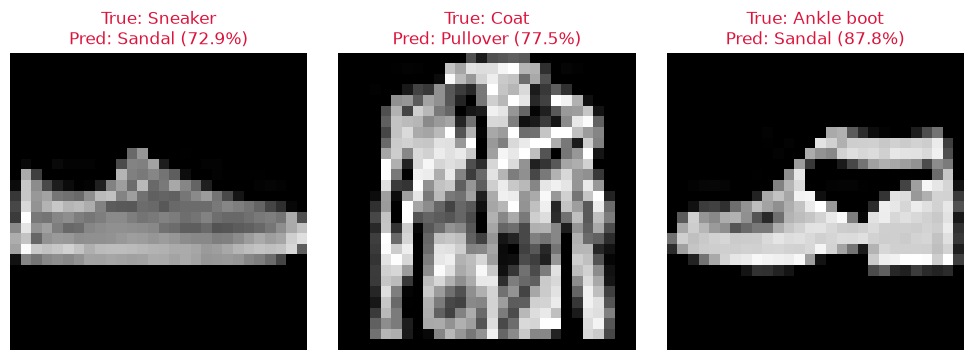

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation="tanh"),
        keras.layers.Dense(10, activation='softmax')
        ])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
    )
early_stopping = keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True,
    monitor="val_loss"
    )
history = model.fit(
    x_train,
    y_train,
    epochs=40,
    validation_data=(x_val, y_val),
    batch_size=batch_size,
    callbacks=[early_stopping]
    )
# evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")

# Draw the confusion matrix
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Find 2 classes the model often confuses
# Fashion MNIST class label mapping
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Create a copy and zero out the diagonal (correct predictions)
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# Find the indices of the single most frequent misclassification: true i predicted as j
true_cls, pred_cls = np.unravel_index(np.argmax(cm_errors), cm_errors.shape)

print(f"Top directional confusion: True '{class_names[true_cls]}' (class {true_cls}) "
      f"predicted as '{class_names[pred_cls]}' (class {pred_cls}) with {cm_errors[true_cls, pred_cls]} errors.\n")

# To find the two classes with the highest bidirectional confusion (i <-> j):
cm_symmetric_errors = cm_errors + cm_errors.T
np.fill_diagonal(cm_symmetric_errors, 0)

# Zero out the lower triangle to avoid counting pairs twice
cm_upper = np.triu(cm_symmetric_errors)
pair_i, pair_j = np.unravel_index(np.argmax(cm_upper), cm_upper.shape)

print(f"The two most confused classes are: '{class_names[pair_i]}' (class {pair_i}) and "
      f"'{class_names[pair_j]}' (class {pair_j}) with {cm_upper[pair_i, pair_j]} total mutual errors.")

# Display three incorrect predictions
# Fashion MNIST class label mapping
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 1. Identify indices of misclassified test samples
incorrect_indices = np.where(y_test != y_pred_classes)[0]

# 2. Select the first 3 incorrect instances
sample_indices = incorrect_indices[:3]

# 3. Plot the misclassified samples
plt.figure(figsize=(10, 3.5))

for i, idx in enumerate(sample_indices):
    plt.subplot(1, 3, i + 1)
    
    # Reshape if x_test is flattened, or display directly if (28, 28)
    image = x_test[idx].reshape(28, 28)
    plt.imshow(image, cmap='gray')
    
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred_classes[idx]]
    confidence = y_pred[idx][y_pred_classes[idx]] * 100
    
    plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", color='crimson')
    plt.axis('off')

plt.tight_layout()
plt.show()